# ENAPRES 2025 · Diagnóstico exhaustivo previo a una red Ising


In [1]:
from pathlib import Path
from datetime import datetime
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font, PatternFill, Border, Side
from openpyxl.utils import get_column_letter
from IPython.display import display, Markdown

RUTA_EXCEL = Path('ENAPRES2025.xlsx')
CARPETA_SALIDA = Path('DIAGNOSTICO_EXHAUSTIVO_PRE_ISING')
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
RUTA_INFORME = CARPETA_SALIDA / 'DIAGNOSTICO_EXHAUSTIVO_PRE_ISING_ENAPRES_7_PROGRAMAS.xlsx'
SEMILLA = 2025
REPLICAS_BOOTSTRAP_PSU = 300

NODOS = {
    'prog_qali_warma': 'Qali Warma',
    'prog_cuna_mas': 'Cuna Más',
    'prog_pension_65': 'Pensión 65',
    'prog_juntos': 'Juntos',
    'prog_vaso_de_leche': 'Vaso de Leche',
    'prog_comedor_popular': 'Comedor Popular',
    'prog_sis': 'SIS',
}
PROGRAMAS = list(NODOS)
IDENTIFICADORES = ['ANIO','MES','CONGLOMERADO','VIVIENDA','HOGAR']

if not RUTA_EXCEL.is_file():
    raise FileNotFoundError(f'No encuentro el archivo: {RUTA_EXCEL.resolve()}')

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 170)
print('Archivo de entrada:', RUTA_EXCEL.resolve())
print('Salida:', RUTA_INFORME.resolve())


Archivo de entrada: /mnt/data/ENAPRES2025_HOGARES_VARIABLES_SELECCIONADAS.xlsx
Salida: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING_ENAPRES_7_PROGRAMAS.xlsx


## 1. Lectura y validación de la estructura


In [2]:
tipos_id = {c:'string' for c in IDENTIFICADORES+['codigo_departamento']}
base = pd.read_excel(RUTA_EXCEL, sheet_name='Base_hogares', dtype=tipos_id, engine='openpyxl')
base.columns = [str(c).strip() for c in base.columns]
columnas_originales = base.columns.tolist()

REQUERIDAS = IDENTIFICADORES + ['factor_hogar','area','codigo_departamento','region_natural',
    'indice_activos_pca','edad_jefe','sexo_jefe','tamano_hogar',
    'n_ninos_0_11','n_adolescentes_12_17','n_adultos_65mas','n_mujeres',
    'hogar_multigeneracional','hogar_con_discapacidad','n_integrantes_con_discapacidad',
    'educacion_jefe_4niveles','lengua_materna_jefe','jefe_pertenece_pueblo_indigena',
    'agua_red_publica','saneamiento_red_publica','electricidad_red_publica',
    'internet_en_hogar','hogar_con_dispositivo_digital'] + PROGRAMAS
no_encontradas = sorted(set(REQUERIDAS) - set(base.columns))
if no_encontradas:
    raise ValueError('Faltan columnas esenciales: '+ ', '.join(no_encontradas))

num = [c for c in columnas_originales if c not in IDENTIFICADORES+['codigo_departamento']]
for c in num:
    base[c] = pd.to_numeric(base[c], errors='coerce')

base['_peso'] = base['factor_hogar'].where(np.isfinite(base['factor_hogar']) & (base['factor_hogar']>0))
base['_psu'] = (base['ANIO'].fillna('SIN_ANIO') + '|' + base['codigo_departamento'].fillna('SIN_DEPA')
                + '|' + base['CONGLOMERADO'].fillna('SIN_CONGL'))
base.loc[base['CONGLOMERADO'].isna() | base['codigo_departamento'].isna(), '_psu'] = pd.NA
base['_menores_18'] = base['n_ninos_0_11'] + base['n_adolescentes_12_17']
base['_n_programas'] = base[PROGRAMAS].sum(axis=1, min_count=1)
base['_n_sin_sis'] = base[[c for c in PROGRAMAS if c != 'prog_sis']].sum(axis=1, min_count=1)

N = len(base)
if N == 0: raise ValueError('La base no contiene registros.')
if base['_peso'].notna().sum() == 0: raise ValueError('No hay pesos positivos utilizables.')

print('Hogares:',f'{N:,}','| Columnas del archivo:', len(columnas_originales),'| Programas:',len(PROGRAMAS))
print('Meses:',sorted(base['MES'].dropna().unique().tolist()))
display(base[PROGRAMAS+['tamano_hogar','area','factor_hogar']].head())


Hogares: 36,184 | Columnas del archivo: 35 | Programas: 7
Meses: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']


,prog_qali_warma,prog_cuna_mas,prog_pension_65,prog_juntos,prog_vaso_de_leche,prog_comedor_popular,prog_sis,tamano_hogar,area,factor_hogar
0,0,0,0,0,0,0,1,5,1,102.582955
1,0,0,0,0,0,0,0,1,1,102.582955
2,0,0,0,0,0,0,0,1,1,102.582955
3,0,0,0,0,0,0,0,1,1,102.582955
4,0,0,0,0,0,0,1,6,1,120.755444


## 2. Calidad: identificadores, nulos, códigos y coherencia interna


In [3]:
def wmean(x, peso):
    a = pd.to_numeric(pd.Series(x),errors='coerce').to_numpy(dtype=float)
    b = pd.to_numeric(pd.Series(peso),errors='coerce').to_numpy(dtype=float)
    m = np.isfinite(a)&np.isfinite(b)&(b>0)
    return float(np.dot(a[m],b[m])/b[m].sum()) if np.any(m) else np.nan

def pct(n,den):
    return (100.0*n/den) if den else np.nan

def wprev(sub,col):
    return 100*wmean(sub[col],sub['_peso'])

def label_area(a):
    return {1:'Urbana',2:'Rural'}.get(a,str(a))

cols_bin = PROGRAMAS + ['jefe_pertenece_pueblo_indigena', 'agua_red_publica',
'saneamiento_red_publica','electricidad_red_publica','hogar_multigeneracional',
'hogar_con_discapacidad','internet_en_hogar','hogar_con_dispositivo_digital']
codigos = {c:{0,1} for c in cols_bin}
codigos.update({'sexo_jefe':{1,2},'area':{1,2},'region_natural':{1,2,3},'educacion_jefe_4niveles':{1,2,3,4}})

faltantes = pd.DataFrame([{'variable':c, 'faltantes':int(base[c].isna().sum()),
    'porcentaje_faltante':pct(int(base[c].isna().sum()),N),
    'distintos_no_nulos':int(base[c].nunique(dropna=True))} for c in columnas_originales])
invalidos = pd.DataFrame([{'variable':c,'valores_inesperados':int((base[c].notna() & ~base[c].isin(val)).sum()),
    'codigos_admitidos':', '.join(map(str,sorted(val)))} for c,val in codigos.items()])

checks = {
'ID de hogar duplicado (incluye mes)':base.duplicated(IDENTIFICADORES,keep=False),
'ID incompleto':base[IDENTIFICADORES].isna().any(axis=1),
'Peso no positivo / no disponible':base['_peso'].isna(),
'Tamaño de hogar menor que 1':base['tamano_hogar'].lt(1)|base['tamano_hogar'].isna(),
'Edad del jefe menor que 15 o mayor que 110':base['edad_jefe'].lt(15)|base['edad_jefe'].gt(110)|base['edad_jefe'].isna(),
'Niños+adolescentes+mayores superan tamaño':base['_menores_18'].add(base['n_adultos_65mas']).gt(base['tamano_hogar']),
'Mujeres superan tamaño':base['n_mujeres'].gt(base['tamano_hogar']),
'Jefe >=65 sin adulto >=65':base['edad_jefe'].ge(65)&base['n_adultos_65mas'].eq(0),
'Discapacidad: indicador difiere del recuento':base['hogar_con_discapacidad'].ne(base['n_integrantes_con_discapacidad'].gt(0).astype(int)),
'Adultos mayores superan tamaño':base['n_adultos_65mas'].gt(base['tamano_hogar']),
'Integrantes con discapacidad superan tamaño':base['n_integrantes_con_discapacidad'].gt(base['tamano_hogar']),
'Conteo de niños/adolescentes/mayores negativo':(base[['n_ninos_0_11','n_adolescentes_12_17','n_adultos_65mas']]<0).any(axis=1),
'Activos PCA no finitos':~np.isfinite(base['indice_activos_pca']),
}
consistencia = pd.DataFrame([{'control':k,'hogares_afectados':int(v.fillna(False).sum()),
    'porcentaje_hogares':pct(int(v.fillna(False).sum()),N)} for k,v in checks.items()])

duplicados_sin_mes = int(base.duplicated(['ANIO','CONGLOMERADO','VIVIENDA','HOGAR']).sum())

print('Principales faltantes:')
display(faltantes.sort_values('faltantes',ascending=False).head(12))
print('Comprobaciones de consistencia:')
display(consistencia)


Principales faltantes:


,variable,faltantes,porcentaje_faltante,distintos_no_nulos
18,jefe_pertenece_pueblo_indigena,2361,6.524983,2
1,MES,0,0.000000,12
0,ANIO,0,0.000000,1
2,CONGLOMERADO,0,0.000000,4493
3,VIVIENDA,0,0.000000,60
5,factor_hogar,0,0.000000,568
4,HOGAR,0,0.000000,5
7,prog_cuna_mas,0,0.000000,2
8,prog_pension_65,0,0.000000,2
9,prog_juntos,0,0.000000,2


Comprobaciones de consistencia:


,control,hogares_afectados,porcentaje_hogares
0,ID de hogar duplicado (incluye mes),0,0.0
1,ID incompleto,0,0.0
2,Peso no positivo / no disponible,0,0.0
3,Tamaño de hogar menor que 1,0,0.0
4,Edad del jefe menor que 15 o mayor que 110,0,0.0
5,Niños+adolescentes+mayores superan tamaño,0,0.0
6,Mujeres superan tamaño,0,0.0
7,Jefe >=65 sin adulto >=65,0,0.0
8,Discapacidad: indicador difiere del recuento,0,0.0
9,Adultos mayores superan tamaño,0,0.0


## 3. Diseño muestral y concentración de pesos


In [4]:
w = base['_peso'].dropna().to_numpy(dtype=float)
peso_total = float(w.sum())
psu_n = int(base['_psu'].nunique(dropna=True))
psu_size = base.groupby('_psu',dropna=True).size()
neff_kish = float(w.sum()**2 / np.sum(w**2))

diseno = pd.DataFrame([
('Hogares observados',N,'Filas únicas con MES en la clave'),
('Hogares con peso positivo',len(w),'factor_hogar > 0'),
('Suma de pesos (hogares expandidos)',peso_total,'No verificable sin documentación oficial'),
('Conglomerados identificados',psu_n,'ANIO + departamento + CONGLOMERADO'),
('Hogares/PSU promedio',float(psu_size.mean()),'Sin estratificación oficial'),
('Hogares/PSU mediana',float(psu_size.median()),'Distribución conglomerados'),
('Peso mínimo',float(w.min()),'Validez administrativa pendiente'),
('Peso mediano',float(np.median(w)),'Validez administrativa pendiente'),
('Peso máximo',float(w.max()),'Validez administrativa pendiente'),
('Razón peso máximo / mínimo',float(w.max()/w.min()),'Variabilidad extrema'),
('CV de pesos',float(w.std(ddof=0)/w.mean()),'Desviación estándar/media'),
('n efectivo Kish (solo pesos)',neff_kish,'No refleja conglomeración ni estratos'),
('Claves duplicadas SIN mes (excluido MES)',duplicados_sin_mes,'No implica necesariamente repetición de viviendas'),
('Claves duplicadas CON mes',int(base.duplicated(IDENTIFICADORES).sum()),'Debería ser 0'),
('Estrato muestral oficial presente',0,'No existe columna de estrato en este archivo'),
],columns=['indicador','valor','nota'])

display(diseno)


,indicador,valor,nota
0,Hogares observados,3.618400e+04,Filas únicas con MES en la clave
1,Hogares con peso positivo,3.618400e+04,factor_hogar > 0
2,Suma de pesos (hogares expandidos),8.918966e+06,No verificable sin documentación oficial
3,Conglomerados identificados,4.493000e+03,ANIO + departamento + CONGLOMERADO
4,Hogares/PSU promedio,8.053416e+00,Sin estratificación oficial
5,Hogares/PSU mediana,7.000000e+00,Distribución conglomerados
6,Peso mínimo,4.061278e-01,Validez administrativa pendiente
7,Peso mediano,1.557433e+02,Validez administrativa pendiente
8,Peso máximo,2.142724e+03,Validez administrativa pendiente
9,Razón peso máximo / mínimo,5.275984e+03,Variabilidad extrema


## 4. Prevalencias: estimación simple, ponderada e intervalos exploratorios por PSU


In [5]:
prevalencias=[]
for c,lbl in NODOS.items():
    x=base[c]
    valido=x.isin([0,1]); valido_w=valido&base['_peso'].notna()
    n_si=int(x.eq(1).sum()); n_no=int(x.eq(0).sum())
    prevalencias.append({'programa':lbl,'variable':c,'hogares_total':N,'hogares_si':n_si,
         'hogares_no':n_no,'sin_dato':int(x.isna().sum()),
         'otros_codigos':int((x.notna()&~valido).sum()),
         'prevalencia_no_ponderada_pct':pct(n_si,int(valido.sum())),
         'prevalencia_ponderada_pct':100*wmean(x.where(valido),base['_peso']),
         'denominador_valido_peso':int(valido_w.sum()),
         'peso_expandido_beneficiarios':float(base.loc[x.eq(1),'_peso'].sum())})
prevalencias=pd.DataFrame(prevalencias)

valid_psu=base['_psu'].notna() & base['_peso'].notna()
tmp=base.loc[valid_psu,['_psu','_peso']+PROGRAMAS].copy()
psu_cod,psus=pd.factorize(tmp['_psu'],sort=True)
G=len(psus)
G_w=np.bincount(psu_cod,weights=tmp['_peso'].to_numpy(),minlength=G)
numP=[];denP=[]
for c in PROGRAMAS:
    valid=tmp[c].isin([0,1]).to_numpy()
    n=np.bincount(psu_cod,weights=(tmp['_peso']*tmp[c].where(tmp[c].isin([0,1]),0)).to_numpy(),minlength=G)
    de=np.bincount(psu_cod,weights=tmp['_peso'].to_numpy()*valid,minlength=G)
    numP.append(n);denP.append(de)
numP=np.column_stack(numP);denP=np.column_stack(denP)
rng=np.random.default_rng(SEMILLA)
if G>1 and REPLICAS_BOOTSTRAP_PSU>0:
    boot_counts=rng.multinomial(G,np.full(G,1/G),size=REPLICAS_BOOTSTRAP_PSU)
    numerator=boot_counts @ numP
    denominator=boot_counts @ denP
    boot=100*np.divide(numerator,denominator,out=np.full_like(numerator,np.nan),where=denominator>0)
else:
    boot=np.full((1,len(PROGRAMAS)),np.nan)

prevalencias['IC_psu_2_5_pct']=[np.nanpercentile(boot[:,i],2.5) for i in range(len(PROGRAMAS))]
prevalencias['IC_psu_97_5_pct']=[np.nanpercentile(boot[:,i],97.5) for i in range(len(PROGRAMAS))]
prevalencias['amplitud_IC_psu_pp']=prevalencias['IC_psu_97_5_pct']-prevalencias['IC_psu_2_5_pct']
prevalencias['PSU_con_algun_beneficiario']=[int(base.loc[base[c].eq(1),'_psu'].nunique()) for c in PROGRAMAS]
prevalencias=prevalencias.sort_values('prevalencia_ponderada_pct',ascending=False).reset_index(drop=True)
display(prevalencias[['programa','hogares_si','sin_dato','prevalencia_no_ponderada_pct','prevalencia_ponderada_pct','IC_psu_2_5_pct','IC_psu_97_5_pct','PSU_con_algun_beneficiario']].round(2))


,programa,hogares_si,sin_dato,prevalencia_no_ponderada_pct,prevalencia_ponderada_pct,IC_psu_2_5_pct,IC_psu_97_5_pct,PSU_con_algun_beneficiario
0,SIS,28639,0,79.15,72.21,71.08,73.19,4382
1,Qali Warma,8134,0,22.48,17.28,16.54,18.05,2769
2,Pensión 65,4531,0,12.52,9.31,8.74,9.80,1843
3,Vaso de Leche,3589,0,9.92,8.07,7.59,8.58,1787
4,Juntos,3358,0,9.28,6.82,6.35,7.30,1313
5,Comedor Popular,1597,0,4.41,3.38,3.05,3.77,646
6,Cuna Más,820,0,2.27,1.50,1.33,1.68,601


## 5. Coincidencia de programas, razón de prevalencias conjuntas, tablas 2×2 y riesgos Ising


In [6]:
from itertools import combinations
pares=[]
mat_11=pd.DataFrame(np.nan,index=PROGRAMAS,columns=PROGRAMAS)
mat_lift=pd.DataFrame(np.nan,index=PROGRAMAS,columns=PROGRAMAS)
mat_phi=pd.DataFrame(np.nan,index=PROGRAMAS,columns=PROGRAMAS)
for a in PROGRAMAS:
    mat_11.loc[a,a]=int(base[a].eq(1).sum())
    mat_lift.loc[a,a]=1.0
    mat_phi.loc[a,a]=1.0

for a,b in combinations(PROGRAMAS,2):
    x=base[a];y=base[b];valid=x.isin([0,1])&y.isin([0,1]);sub=base.loc[valid]
    x=x[valid].to_numpy(dtype=int);y=y[valid].to_numpy(dtype=int)
    p=sub['_peso'].to_numpy(dtype=float)
    n11=int(((x==1)&(y==1)).sum());n10=int(((x==1)&(y==0)).sum())
    n01=int(((x==0)&(y==1)).sum());n00=int(((x==0)&(y==0)).sum())
    n=len(x)
    w11=float(p[(x==1)&(y==1)].sum());w10=float(p[(x==1)&(y==0)].sum());w01=float(p[(x==0)&(y==1)].sum());w00=float(p[(x==0)&(y==0)].sum());wt=w11+w10+w01+w00
    wa=(w11+w10)/wt if wt else np.nan;wb=(w11+w01)/wt if wt else np.nan;wab=w11/wt if wt else np.nan
    lift=wab/(wa*wb) if wa*wb>0 else np.nan
    phi=(n11*n00-n10*n01)/np.sqrt((n11+n10)*(n01+n00)*(n11+n01)*(n10+n00)) if (n11+n10)*(n01+n00)*(n11+n01)*(n10+n00)>0 else np.nan
    odds=((n11+0.5)*(n00+0.5))/((n10+0.5)*(n01+0.5))
    cpBa=n11/(n11+n10) if n11+n10 else np.nan
    cpAb=n11/(n11+n01) if n11+n01 else np.nan
    near_sep=bool(min(n11,n10,n01,n00)<=10)
    anida=bool(cpBa>=0.98 or cpAb>=0.98)
    alerta=('CELDA <= 10; ' if near_sep else '')+('COINCIDENCIA < 50; ' if n11<50 else '')+('COBERTURA CASI ANIDADA >=98%; ' if anida else '')
    pares.append({'programa_A':NODOS[a],'programa_B':NODOS[b],'variable_A':a,'variable_B':b,
     'n_validos':n,'n11_ambos_si':n11,'n10_solo_A':n10,'n01_solo_B':n01,'n00_ambos_no':n00,
     'n_esperado_11_independencia':(n11+n10)*(n11+n01)/n if n else np.nan,
     'total_ponderado_11':w11,'pct_ponderado_ambos_si':100*wab,
     'pct_B_dado_A_no_pond':100*cpBa,'pct_A_dado_B_no_pond':100*cpAb,
     'pct_B_dado_A_pond':100*w11/(w11+w10) if w11+w10 else np.nan,
     'pct_A_dado_B_pond':100*w11/(w11+w01) if w11+w01 else np.nan,
     'lift_ponderado':lift,'phi_no_ponderado':phi,'odds_ratio_Haldane_no_ponderada':odds,
     'celda_minima_2x2':min(n11,n10,n01,n00),'alerta_estimacion':alerta.strip()})
    for i,j in [(a,b),(b,a)]:
        mat_11.loc[i,j]=n11;mat_lift.loc[i,j]=lift;mat_phi.loc[i,j]=phi
pares=pd.DataFrame(pares).sort_values('n11_ambos_si',ascending=False)

boot_pares=[]
wt_psu=np.bincount(psu_cod,weights=tmp['_peso'].to_numpy(dtype=float),minlength=G)
for par in pares.itertuples(index=False):
    a,b=par.variable_A,par.variable_B
    valid=tmp[a].isin([0,1]).to_numpy()&tmp[b].isin([0,1]).to_numpy()
    wa=tmp['_peso'].to_numpy(dtype=float)
    x=tmp[a].to_numpy(dtype=float);y=tmp[b].to_numpy(dtype=float)
    s11=np.bincount(psu_cod,weights=np.where(valid&(x==1)&(y==1),wa,0),minlength=G)
    sa=np.bincount(psu_cod,weights=np.where(valid&(x==1),wa,0),minlength=G)
    sb=np.bincount(psu_cod,weights=np.where(valid&(y==1),wa,0),minlength=G)
    st=np.bincount(psu_cod,weights=np.where(valid,wa,0),minlength=G)
    b11=boot_counts@s11
    ba=boot_counts@sa
    bb=boot_counts@sb
    bt=boot_counts@st
    liftb=np.divide(b11*bt,ba*bb,out=np.full_like(b11,np.nan),where=(ba>0)&(bb>0))
    boot_pares.append({'variable_A':a,'variable_B':b,'programa_A':NODOS[a],'programa_B':NODOS[b],
        'lift_puntual_ponderado':par.lift_ponderado,
        'IC_lift_2_5_PSU_exploratorio':float(np.nanpercentile(liftb,2.5)),
        'IC_lift_97_5_PSU_exploratorio':float(np.nanpercentile(liftb,97.5)),
        'porcentaje_replicas_lift_mayor_1':float(100*np.nanmean(liftb>1)),
        'replicas':len(liftb),
        'nota':'Estabilidad MARGINAL del lift, NO estabilidad de conexiones Ising.'})
boot_pares=pd.DataFrame(boot_pares)
print('Número de pares:',len(pares))
display(pares[['programa_A','programa_B','n11_ambos_si','n10_solo_A','n01_solo_B',
    'pct_B_dado_A_no_pond','pct_A_dado_B_no_pond','lift_ponderado','phi_no_ponderado','alerta_estimacion']].head(12).round(3))


Número de pares: 21


,programa_A,programa_B,n11_ambos_si,n10_solo_A,n01_solo_B,pct_B_dado_A_no_pond,pct_A_dado_B_no_pond,lift_ponderado,phi_no_ponderado,alerta_estimacion
5,Qali Warma,SIS,7494,640,21145,92.132,26.167,1.261,0.172,
14,Pensión 65,SIS,4473,58,24166,98.720,15.619,1.363,0.182,COBERTURA CASI ANIDADA >=98%;
19,Vaso de Leche,SIS,3435,154,25204,95.709,11.994,1.296,0.135,
17,Juntos,SIS,3351,7,25288,99.792,11.701,1.381,0.163,CELDA <= 10; COBERTURA CASI ANIDADA >=98%;
2,Qali Warma,Juntos,2024,6110,1334,24.883,60.274,3.369,0.290,
3,Qali Warma,Vaso de Leche,1950,6184,1639,23.973,54.333,2.903,0.253,
20,Comedor Popular,SIS,1518,79,27121,95.053,5.300,1.310,0.084,
15,Juntos,Vaso de Leche,1219,2139,2370,36.301,33.965,4.309,0.282,
10,Cuna Más,SIS,797,23,27842,97.195,2.783,1.335,0.068,
8,Cuna Más,Vaso de Leche,516,304,3073,62.927,14.377,7.759,0.270,


## 6. Elegibilidad: proxies de edad y alcance real de los criterios


In [7]:
reglas={
'prog_qali_warma':(base['_menores_18']>0,'Algún integrante de 0 a 17 años (escolaridad no observada)'),
'prog_cuna_mas':(base['n_ninos_0_11']>0,'Algún niño de 0 a 11 años (no identifica 0-3 años)'),
'prog_pension_65':(base['n_adultos_65mas']>0,'Algún integrante de 65 años o más'),
'prog_juntos':(base['_menores_18']>0,'Menores de 18; no incluye gestantes sin menores'),
'prog_vaso_de_leche':(base['n_ninos_0_11']>0,'Niños 0-11; no cubre todas las poblaciones atendidas'),
}
rows=[]
for c,lbl in NODOS.items():
    if c in reglas:
        mask,criterio=reglas[c]
        conocido=mask.notna()
        fuera=(~mask)&conocido
        dentro=mask&conocido
        rows.append({'programa':lbl,'proxy_edad':criterio,'hogares_con_proxy':int(dentro.sum()),
         'hogares_sin_proxy':int(fuera.sum()),'beneficiarios_con_proxy':int((dentro&base[c].eq(1)).sum()),
         'beneficiarios_sin_proxy':int((fuera&base[c].eq(1)).sum()),
         'tasa_si_con_proxy_pct':pct(int((dentro&base[c].eq(1)).sum()),int(dentro.sum())),
         'prevalencia_pond_con_proxy_pct':wprev(base.loc[dentro],c),
         'cero_fuera_proxy':int((fuera&base[c].eq(0)).sum()),
         'nota':'Solo filtro demográfico aproximado; no determina elegibilidad.'})
    else:
        rows.append({'programa':lbl,'proxy_edad':'No definido: cobertura no restringida aquí',
         'hogares_con_proxy':np.nan,'hogares_sin_proxy':np.nan,'beneficiarios_con_proxy':np.nan,
         'beneficiarios_sin_proxy':np.nan,'tasa_si_con_proxy_pct':np.nan,
         'prevalencia_pond_con_proxy_pct':np.nan,'cero_fuera_proxy':np.nan,
         'nota':'Sin proxy etario adecuado en este Excel.'})
elegibilidad=pd.DataFrame(rows)

prox_pares=[]
for a,b in combinations(PROGRAMAS,2):
    if a in reglas and b in reglas:
        universo=reglas[a][0]&reglas[b][0]
        prox_pares.append({'programa_A':NODOS[a],'programa_B':NODOS[b],
          'hogares_con_ambos_proxies':int(universo.sum()),
          'hogares_con_ambos_programas_y_ambos_proxies':int((universo&base[a].eq(1)&base[b].eq(1)).sum()),
          'prevalencia_conjunta_en_universo_pct':pct(int((universo&base[a].eq(1)&base[b].eq(1)).sum()),int(universo.sum())),
          'nota':'No representa elegibilidad real del par.'})
proxies_pares=pd.DataFrame(prox_pares)
display(elegibilidad.round(2))


,programa,proxy_edad,hogares_con_proxy,hogares_sin_proxy,beneficiarios_con_proxy,beneficiarios_sin_proxy,tasa_si_con_proxy_pct,prevalencia_pond_con_proxy_pct,cero_fuera_proxy,nota
0,Qali Warma,Algún integrante de 0 a 17 años (escolaridad n...,17671.0,18513.0,8134.0,0.0,46.03,37.92,18513.0,Solo filtro demográfico aproximado; no determi...
1,Cuna Más,Algún niño de 0 a 11 años (no identifica 0-3 a...,12991.0,23193.0,820.0,0.0,6.31,4.56,23193.0,Solo filtro demográfico aproximado; no determi...
2,Pensión 65,Algún integrante de 65 años o más,11354.0,24830.0,4531.0,0.0,39.91,26.86,24830.0,Solo filtro demográfico aproximado; no determi...
3,Juntos,Menores de 18; no incluye gestantes sin menores,17671.0,18513.0,3341.0,17.0,18.91,14.90,18496.0,Solo filtro demográfico aproximado; no determi...
4,Vaso de Leche,Niños 0-11; no cubre todas las poblaciones ate...,12991.0,23193.0,3014.0,575.0,23.20,20.23,22618.0,Solo filtro demográfico aproximado; no determi...
5,Comedor Popular,No definido: cobertura no restringida aquí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sin proxy etario adecuado en este Excel.
6,SIS,No definido: cobertura no restringida aquí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sin proxy etario adecuado en este Excel.


## 7. Cobertura conjunta por hogar y sensibilidad a excluir SIS


In [8]:
distribuciones=[]
for etiqueta,c in [('7 programas','_n_programas'),('6 programas, sin SIS','_n_sin_sis')]:
    for k in sorted(base[c].dropna().unique()):
        sub=base[base[c].eq(k)]
        distribuciones.append({'escenario':etiqueta,'n_programas':int(k),
        'hogares':len(sub),'porcentaje_muestral':100*len(sub)/N,
        'suma_pesos':float(sub['_peso'].sum()),'porcentaje_ponderado':100*sub['_peso'].sum()/peso_total})
distribucion=pd.DataFrame(distribuciones)

sin_programa=(base['_n_programas']==0)
solo_sis=(base['_n_programas']==1)&base['prog_sis'].eq(1)
alguno_no_sis=base['_n_sin_sis'].gt(0)
mas_de_uno_no_sis=base['_n_sin_sis'].ge(2)

sensibilidad=pd.DataFrame([
    ('Ningún programa (incluido SIS)',sin_programa),
    ('Únicamente SIS',solo_sis),
    ('Alguno de los 6 programas sin SIS',alguno_no_sis),
    ('Dos o más programas sin SIS',mas_de_uno_no_sis),
    ('Dos o más programas incluyendo SIS',base['_n_programas'].ge(2)),
],columns=['grupo','mascara'])
sensibilidad['hogares']=sensibilidad['mascara'].map(lambda m:int(m.sum()))
sensibilidad['pct_muestral']=100*sensibilidad['hogares']/N
sensibilidad['pct_ponderado']=sensibilidad['mascara'].map(lambda m:100*base.loc[m,'_peso'].sum()/peso_total)
sensibilidad=sensibilidad.drop(columns=['mascara'])
display(sensibilidad.round(2))


,grupo,hogares,pct_muestral,pct_ponderado
0,Ningún programa (incluido SIS),6687,18.48,25.64
1,Únicamente SIS,14405,39.81,41.80
2,Alguno de los 6 programas sin SIS,15092,41.71,32.57
3,Dos o más programas sin SIS,4975,13.75,10.12
4,Dos o más programas incluyendo SIS,14322,39.58,30.68


## 8. Heterogeneidad territorial, índice de activos y otras covariables


In [9]:
def tabla_por_grupo(df,col,etiquetador=None):
    filas=[]
    for val,sub in df.groupby(col,dropna=False):
        r={'grupo':str(val) if etiquetador is None else etiquetador(val), 'variable_grupo':col,
            'hogares':len(sub),'PSU':sub['_psu'].nunique(),'peso_total':sub['_peso'].sum()}
        for p in PROGRAMAS: r[NODOS[p]+'_pct']=wprev(sub,p)
        filas.append(r)
    return pd.DataFrame(filas)

areas=tabla_por_grupo(base,'area',label_area)
departamentos=tabla_por_grupo(base,'codigo_departamento')
regiones=tabla_por_grupo(base,'region_natural')

a=base['indice_activos_pca'].to_numpy(dtype=float)
valid=(np.isfinite(a)&base['_peso'].notna().to_numpy())
xa=a[valid];wa=base.loc[valid,'_peso'].to_numpy(dtype=float)
orden=np.argsort(xa)
qs=(np.cumsum(wa[orden])-0.5*wa[orden])/wa.sum()
cortes=np.interp([.2,.4,.6,.8],qs,xa[orden])
base['_quintil_activos']=pd.Series(pd.NA,index=base.index,dtype='Int64')
base.loc[valid,'_quintil_activos']=(np.searchsorted(cortes,xa,side='right')+1).astype(int)
activos=tabla_por_grupo(base,'_quintil_activos')
activos['promedio_pca_ponderado']=[wmean(sub['indice_activos_pca'],sub['_peso']) for _,sub in base.groupby('_quintil_activos')]
activos['porcentaje_con_internet']=[wprev(sub,'internet_en_hogar') for _,sub in base.groupby('_quintil_activos')]
activos['porcentaje_con_electricidad']=[wprev(sub,'electricidad_red_publica') for _,sub in base.groupby('_quintil_activos')]

controles=['edad_jefe','tamano_hogar','n_ninos_0_11','n_adolescentes_12_17','n_adultos_65mas',
 'n_mujeres','n_integrantes_con_discapacidad','indice_activos_pca','agua_red_publica',
 'saneamiento_red_publica','electricidad_red_publica','internet_en_hogar',
 'hogar_con_dispositivo_digital','jefe_pertenece_pueblo_indigena']
perfil=[]
for c in controles:
    fila={'control':c,'tipo':'media/tasa ponderada','total':wmean(base[c],base['_peso']),
        'faltantes':int(base[c].isna().sum())}
    for p in PROGRAMAS:
        sub=base[base[p].eq(1)]
        fila['beneficiarios_'+NODOS[p]]=wmean(sub[c],sub['_peso'])
    perfil.append(fila)
perfil=pd.DataFrame(perfil)

print('Tasas ponderadas por área:')
display(areas.round(2))
print('Por quintiles ponderados del PCA:')
display(activos.round(2))


Tasas ponderadas por área:


,grupo,variable_grupo,hogares,PSU,peso_total,Qali Warma_pct,Cuna Más_pct,Pensión 65_pct,Juntos_pct,Vaso de Leche_pct,Comedor Popular_pct,SIS_pct
0,Urbana,area,22269,3558,6970978.00,14.64,0.86,4.58,2.96,6.05,2.16,66.4
1,Rural,area,13915,935,1947988.28,26.73,3.78,26.21,20.64,15.32,7.75,93.0


Por quintiles ponderados del PCA:


,grupo,variable_grupo,hogares,PSU,peso_total,Qali Warma_pct,Cuna Más_pct,Pensión 65_pct,Juntos_pct,Vaso de Leche_pct,Comedor Popular_pct,SIS_pct,promedio_pca_ponderado,porcentaje_con_internet,porcentaje_con_electricidad
0,1,_quintil_activos,10021,2501,1781761.06,19.40,2.65,30.75,15.59,11.52,6.67,90.05,-1.39,0.08,80.52
1,2,_quintil_activos,8966,3367,1782829.37,23.71,2.39,9.07,11.70,11.90,4.56,83.69,-0.65,6.29,90.21
2,3,_quintil_activos,7220,3280,1742914.55,20.49,1.34,4.37,5.41,8.70,3.23,76.27,-0.02,27.86,93.50
3,4,_quintil_activos,5742,2924,1823602.34,15.15,0.61,1.91,1.26,5.85,2.05,65.13,0.64,59.83,96.48
4,5,_quintil_activos,4235,2196,1787858.96,7.79,0.52,0.54,0.27,2.48,0.43,46.23,1.40,94.04,98.28


## 9. Factibilidad Ising, información escasa y alertas previas


In [10]:
completos=base[PROGRAMAS].isin([0,1]).all(axis=1)
completos_peso=completos&base['_peso'].notna()&base['_psu'].notna()
subset=base.loc[completos_peso]
filas_fact=[]
for c,lbl in NODOS.items():
    npos=int(subset[c].eq(1).sum()); nneg=int(subset[c].eq(0).sum())
    psu_pos=int(subset.loc[subset[c].eq(1),'_psu'].nunique())
    celdas_bajas=int(((((pares['variable_A']==c)|(pares['variable_B']==c))&((pares['celda_minima_2x2']<=10)|(pares['n11_ambos_si']<50)))).sum())
    a='ATENCION' if npos<500 or psu_pos<100 or celdas_bajas else 'REVISAR'
    filas_fact.append({'programa':lbl,'positivos':npos,'negativos':nneg,
      'prevalencia_pct':pct(npos,len(subset)),'PSU_con_positivos':psu_pos,
      'pares_con_alerta_celda_<=10_o_cooc_<50':celdas_bajas,'diagnostico_preliminar':a,
      'nota':'Criterios descriptivos, no umbrales formales ni prueba de estabilidad.'})
factibilidad=pd.DataFrame(filas_fact)

incidencias=[
('CRITICA','Los programas tienen 0 faltantes en este Excel, pero el archivo no conserva respuestas CAP300 originales ni códigos de salto; no se puede auditar si todos los 0 son legítimos.'),
('ALTA','Hay tablas 2x2 con celdas muy pequeñas, pocas coincidencias o asociaciones casi deterministas; revisar separación antes de regresiones por nodo.'),
('ALTA','Los proxies de edad no representan reglas administrativas completas de elegibilidad y no deben usarse para excluir/recodificar automáticamente.'),
('ALTA','No se dispone de estrato oficial, por lo cual los IC PSU bootstrap son aproximaciones no oficiales.'),
('MEDIA','El índice PCA es solo un puntaje; no están disponibles bienes, cargas ni varianza explicada para auditar la construcción del indicador.'),
('MEDIA','El peso factor_hogar y su apropiación para la unidad hogar deben validarse con el manual metodológico oficial.'),
('MEDIA','Las comparaciones territoriales y socioeconómicas son marginales, no ajustes de redes Ising.'),
('MEDIA','Comprobar escala y códigos de lengua materna/educación antes de incluir dummies en el modelo.'),
]
alertas=pd.DataFrame(incidencias,columns=['prioridad','observacion'])

resumen=pd.DataFrame([
    ('Hogares',N),('Columnas del archivo original',len(columnas_originales)),('Nodos sociales',len(PROGRAMAS)),
    ('PSU (aprox.)',psu_n),('Hogares completos en nodos',int(completos.sum())),
    ('Hogares completos con peso y PSU',len(subset)),
    ('Nodos con faltantes',int((base[PROGRAMAS].isna().sum()>0).sum())),
    ('Faltantes pertenencia indígena',int(base['jefe_pertenece_pueblo_indigena'].isna().sum())),
    ('Faltantes pertenencia indígena (%)',pct(int(base['jefe_pertenece_pueblo_indigena'].isna().sum()),N)),
    ('Pares entre programas',len(pares)),
    ('Pares con alguna celda <=10',int((pares['celda_minima_2x2']<=10).sum())),
    ('Pares con menos de 50 coocurrencias',int((pares['n11_ambos_si']<50).sum())),
    ('Pares con condición >=98% A|B o B|A',int(((pares['pct_A_dado_B_no_pond']>=98)|(pares['pct_B_dado_A_no_pond']>=98)).sum())),
    ('Media de programas por hogar (sin ponderar)',float(base['_n_programas'].mean())),
    ('Media de programas por hogar (ponderada)',wmean(base['_n_programas'],base['_peso'])),
    ('Media de programas sin SIS (ponderada)',wmean(base['_n_sin_sis'],base['_peso'])),
    ('Hogares sin ninguno (n)',int(sin_programa.sum())),
    ('Hogares solamente SIS (n)',int(solo_sis.sum())),
    ('Con alguno de los 6 sin SIS (%) ponderado',float(sensibilidad.loc[sensibilidad.grupo.eq('Alguno de los 6 programas sin SIS'),'pct_ponderado'].iloc[0])),
    ('n efectivo Kish - solo pesos',neff_kish),
],columns=['indicador','valor'])

print('Resumen numérico:')
display(resumen)
print('Alertas de factibilidad:')
display(factibilidad)


Resumen numérico:


,indicador,valor
0,Hogares,36184.000000
1,Columnas del archivo original,35.000000
2,Nodos sociales,7.000000
3,PSU (aprox.),4493.000000
4,Hogares completos en nodos,36184.000000
5,Hogares completos con peso y PSU,36184.000000
6,Nodos con faltantes,0.000000
7,Faltantes pertenencia indígena,2361.000000
8,Faltantes pertenencia indígena (%),6.524983
9,Pares entre programas,21.000000


Alertas de factibilidad:


,programa,positivos,negativos,prevalencia_pct,PSU_con_positivos,pares_con_alerta_celda_<=10_o_cooc_<50,diagnostico_preliminar,nota
0,Qali Warma,8134,28050,22.479549,2769,0,REVISAR,"Criterios descriptivos, no umbrales formales n..."
1,Cuna Más,820,35364,2.266195,601,1,ATENCION,"Criterios descriptivos, no umbrales formales n..."
2,Pensión 65,4531,31653,12.522109,1843,1,ATENCION,"Criterios descriptivos, no umbrales formales n..."
3,Juntos,3358,32826,9.280345,1313,1,ATENCION,"Criterios descriptivos, no umbrales formales n..."
4,Vaso de Leche,3589,32595,9.918749,1787,0,REVISAR,"Criterios descriptivos, no umbrales formales n..."
5,Comedor Popular,1597,34587,4.413553,646,0,REVISAR,"Criterios descriptivos, no umbrales formales n..."
6,SIS,28639,7545,79.148242,4382,1,ATENCION,"Criterios descriptivos, no umbrales formales n..."


## 10. Gráficos reproducibles


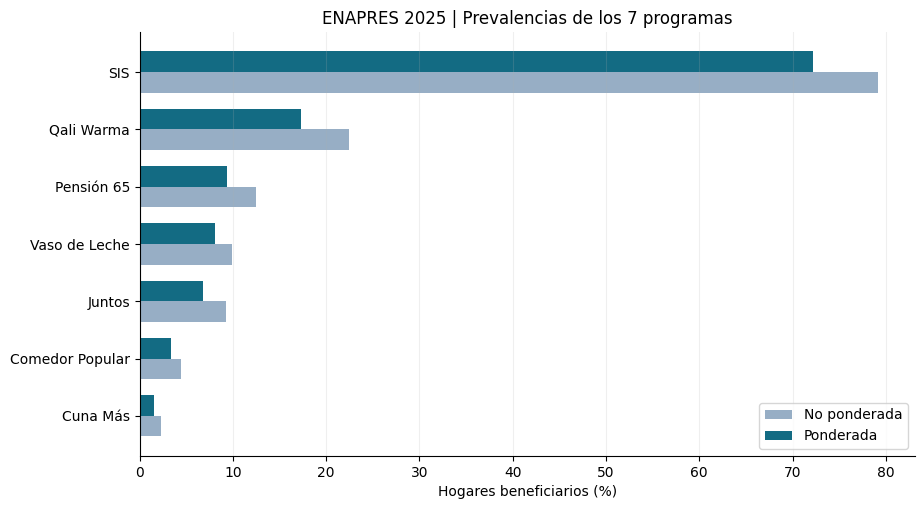

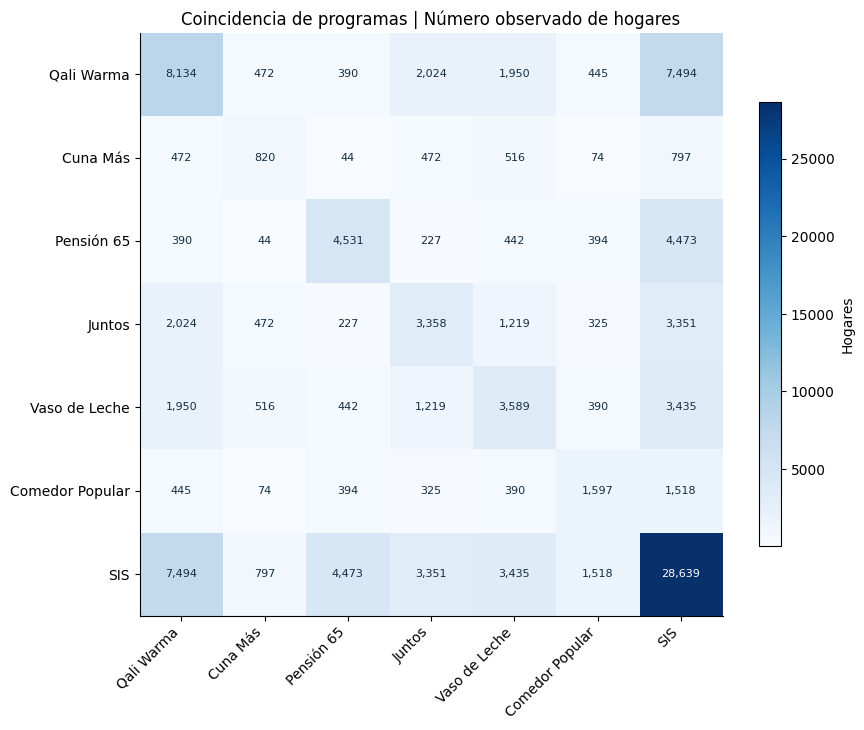

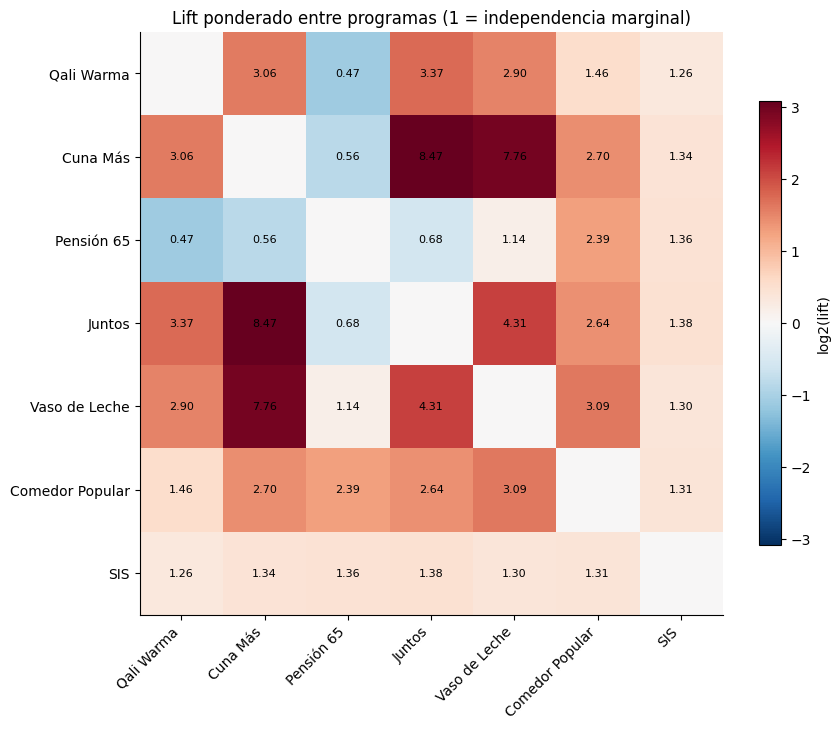

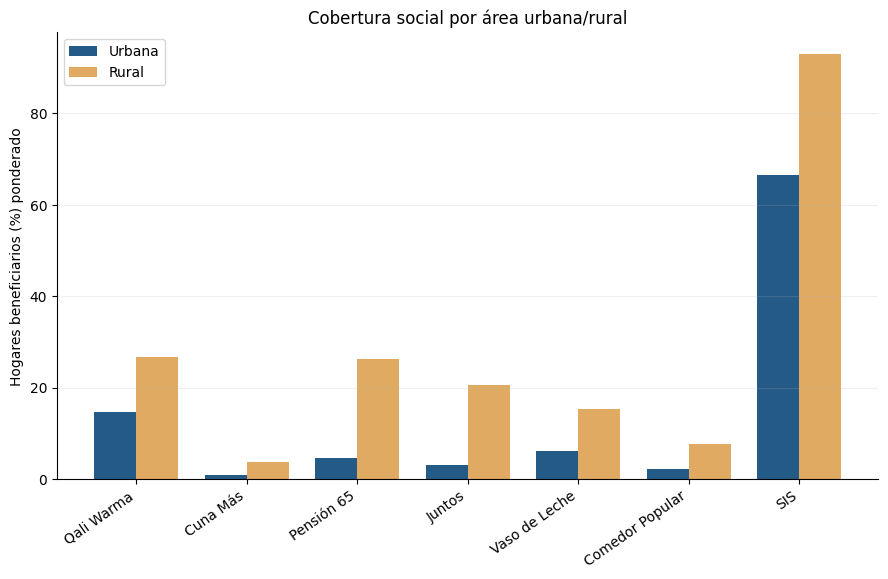

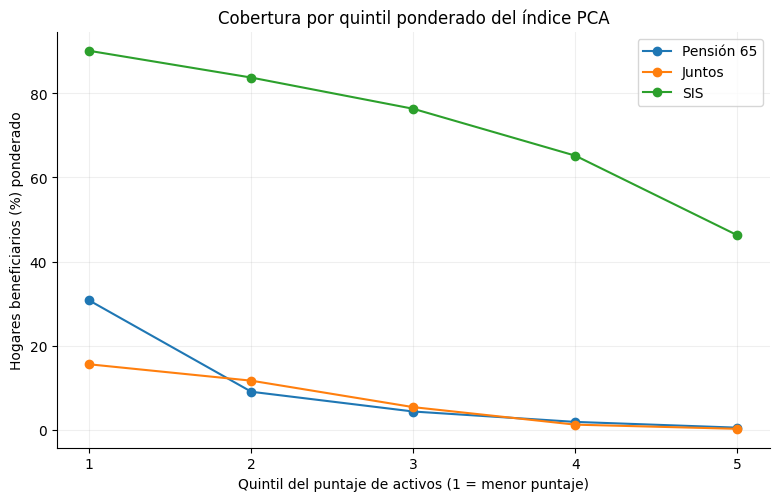

In [11]:
plt.rcParams.update({'font.size':10, 'axes.spines.top':False,'axes.spines.right':False, 'savefig.dpi':165})

def guardar_fig(nombre):
    ruta=CARPETA_SALIDA/nombre
    plt.savefig(ruta,bbox_inches='tight')
    plt.show()
    plt.close()
    return ruta

pr=prevalencias.sort_values('prevalencia_ponderada_pct')
fig,ax=plt.subplots(figsize=(10,5.5))
y=np.arange(len(pr))
ax.barh(y-0.18,pr['prevalencia_no_ponderada_pct'],height=0.36,label='No ponderada',color='#97aec5')
ax.barh(y+0.18,pr['prevalencia_ponderada_pct'],height=0.36,label='Ponderada',color='#136b83')
ax.set_yticks(y,pr['programa']); ax.set_xlabel('Hogares beneficiarios (%)')
ax.set_title('ENAPRES 2025 | Prevalencias de los 7 programas')
ax.legend(loc='lower right'); ax.grid(axis='x',alpha=0.2)
graf_prev=guardar_fig('01_PREVALENCIAS_7_PROGRAMAS.png')

mat=mat_11.loc[PROGRAMAS,PROGRAMAS].to_numpy(dtype=float)
fig,ax=plt.subplots(figsize=(9.4,8))
im=ax.imshow(mat,cmap='Blues')
ax.set_xticks(range(7),[NODOS[x] for x in PROGRAMAS],rotation=45,ha='right')
ax.set_yticks(range(7),[NODOS[x] for x in PROGRAMAS])
for i in range(7):
    for j in range(7):
        ax.text(j,i,f'{int(mat[i,j]):,}',ha='center',va='center',fontsize=8,
            color='white' if mat[i,j]>np.nanmax(mat)*0.54 else '#142c41')
ax.set_title('Coincidencia de programas | Número observado de hogares')
fig.colorbar(im,ax=ax,shrink=.72,label='Hogares')
graf_cooc=guardar_fig('02_MATRIZ_COINCIDENCIA.png')

liftarray=mat_lift.loc[PROGRAMAS,PROGRAMAS].to_numpy(dtype=float)
log2lift=np.log2(np.clip(liftarray,1e-9,None))
lim=max(1.0,float(np.nanmax(np.abs(log2lift))))
fig,ax=plt.subplots(figsize=(9.4,8))
im=ax.imshow(log2lift,cmap='RdBu_r',vmin=-lim,vmax=lim)
ax.set_xticks(range(7),[NODOS[x] for x in PROGRAMAS],rotation=45,ha='right')
ax.set_yticks(range(7),[NODOS[x] for x in PROGRAMAS])
for i in range(7):
    for j in range(7):
        if i!=j:
            ax.text(j,i,f'{liftarray[i,j]:.2f}',ha='center',va='center',fontsize=8)
ax.set_title('Lift ponderado entre programas (1 = independencia marginal)')
fig.colorbar(im,ax=ax,shrink=.72,label='log2(lift)')
graf_lift=guardar_fig('03_LIFT_PONDERADO.png')

fig,ax=plt.subplots(figsize=(10.6,5.8))
xx=np.arange(len(PROGRAMAS));ancho=.38
for k,(area,sub) in enumerate(base.groupby('area')):
    values=[wprev(sub,c) for c in PROGRAMAS]
    ax.bar(xx+(k-.5)*ancho,values,width=ancho,label=label_area(area),color=['#245a86','#e0aa62'][k])
ax.set_xticks(xx,[NODOS[c] for c in PROGRAMAS],rotation=35,ha='right')
ax.set_ylabel('Hogares beneficiarios (%) ponderado')
ax.set_title('Cobertura social por área urbana/rural')
ax.legend();ax.grid(axis='y',alpha=.2)
graf_area=guardar_fig('04_COBERTURA_AREA.png')

fig,ax=plt.subplots(figsize=(9.2,5.4))
ax.plot(activos['grupo'],activos['Pensión 65_pct'],marker='o',label='Pensión 65')
ax.plot(activos['grupo'],activos['Juntos_pct'],marker='o',label='Juntos')
ax.plot(activos['grupo'],activos['SIS_pct'],marker='o',label='SIS')
ax.set_title('Cobertura por quintil ponderado del índice PCA')
ax.set_xlabel('Quintil del puntaje de activos (1 = menor puntaje)')
ax.set_ylabel('Hogares beneficiarios (%) ponderado');ax.grid(alpha=.2);ax.legend()
graf_pca=guardar_fig('05_PREVALENCIAS_ACTIVOS.png')


## 11. Exportación de resultados a Excel


In [12]:
notas=pd.DataFrame([
('Alcance','Diagnóstico descriptivo pre-Ising de ENAPRES 2025, 7 programas, unidad hogar.'),
('Fuente','ENAPRES2025.xlsx; hoja Base_hogares.'),
('Indicador principal','1 = al menos un integrante beneficiario; 0 = ningún integrante según codificación de la base.'),
('Límite de los ceros','No verificable desde el Excel si un 0 provino de 2=No, pase, o respuesta faltante en CAP300.'),
('Factor','Se usa factor_hogar tal como fue entregado; no se verificó contra documento oficial.'),
('Conglomerado','PSU aproximada = año + departamento + CONGLOMERADO; se incluye MES solo en identificador de hogar.'),
('Intervalos','Bootstrap no estratificado por conglomerados: intervalos exploratorios, NO oficiales.'),
('Elegibilidad','Los proxies de edad describen hogares, NO comprueban elegibilidad administrativa o ingreso/pobreza.'),
('Qali Warma','Se usa indicador consolidado, sin desagregar desayuno y almuerzo.'),
('Cuna Más','Se usa indicador consolidado; variable de niños 0-11 no identifica menores de 3 años.'),
('PCA','Sólo se audita puntaje índice_activos_pca; no es posible rehacer el PCA sin variables de bienes.'),
('Interpretación','Lift y phi son asociaciones marginales; no equivalen a coeficientes de una red Ising.'),
('Bootstrap lift','Los IC y la frecuencia lift>1 remuestrean PSU; NO representan estabilidad de aristas ni intervalos oficiales.'),
('Próximo paso','Validar CAP300, ponderación y estratos; luego ajustar Ising con covariables y pruebas de estabilidad.'),
],columns=['tema','aclaracion'])

hojas={
'00_LEEME':notas,
'01_RESUMEN':resumen,
'02_ALERTAS':alertas,
'03_PREVALENCIAS':prevalencias,
'04_TABLAS_2x2':pares,
'04B_BOOT_LIFT':boot_pares,
'05_MATRIZ_N11':mat_11.rename(index=NODOS,columns=NODOS).reset_index().rename(columns={'index':'Programa'}),
'06_MATRIZ_LIFT':mat_lift.rename(index=NODOS,columns=NODOS).reset_index().rename(columns={'index':'Programa'}),
'07_MATRIZ_PHI':mat_phi.rename(index=NODOS,columns=NODOS).reset_index().rename(columns={'index':'Programa'}),
'08_ELEGIBILIDAD_EDAD':elegibilidad,
'09_PROXIES_PARES':proxies_pares,
'10_COBERTURA_HOGAR':distribucion,
'11_SENSIBILIDAD_SIS':sensibilidad,
'12_DISENO_PESOS':diseno,
'13_FALTANTES':faltantes,
'14_VALORES_INVALIDOS':invalidos,
'15_INCONSISTENCIAS':consistencia,
'16_AREA':areas,
'17_DEPARTAMENTO':departamentos,
'18_REGION_NATURAL':regiones,
'19_QUINTILES_PCA':activos,
'20_PERFIL_CONTROLES':perfil,
'21_FACTIBILIDAD_ISING':factibilidad,
}

with pd.ExcelWriter(RUTA_INFORME,engine='openpyxl') as writer:
    for titulo,df in hojas.items():
        df.to_excel(writer,sheet_name=titulo,index=False)

wb=load_workbook(RUTA_INFORME)
for ws in wb:
    ws.sheet_view.showGridLines=False
    ws.freeze_panes='B2'
    ws.auto_filter.ref=ws.dimensions
    ws.row_dimensions[1].height=27
    for cell in ws[1]:
        cell.fill=PatternFill('solid',fgColor='153A55')
        cell.font=Font(name='Aptos',size=10,bold=True,color='FFFFFF')
        cell.alignment=Alignment(vertical='center',wrap_text=True)
    for j,col in enumerate(ws.columns,1):
        colcells=list(col)
        header=str(colcells[0].value or '')
        if header in ['aclaracion','observacion','nota','proxy_edad','alerta_estimacion','control','indicador','grupo']:
            width=52 if header in ['aclaracion','observacion','nota','proxy_edad'] else 32
        elif 'programa' in header.lower():
            width=26
        else:
            width=max(13,min(29,len(header)+3))
        ws.column_dimensions[get_column_letter(j)].width=width
        for cell in colcells[1:]:
            cell.alignment=Alignment(vertical='center')
            if isinstance(cell.value,float):
                cell.number_format='#,##0.000' if 'coef' in header.lower() or 'lift' in header.lower() or 'phi' in header.lower() else '#,##0.00'
    ws.sheet_properties.pageSetUpPr.fitToPage=True
wb.save(RUTA_INFORME)

print('Informe Excel:',RUTA_INFORME.resolve())
print('Número de hojas:',len(hojas))
for pth in [graf_prev,graf_cooc,graf_lift,graf_area,graf_pca]: print('Gráfico:',pth.resolve())


Informe Excel: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING_ENAPRES_7_PROGRAMAS.xlsx
Número de hojas: 23
Gráfico: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/01_PREVALENCIAS_7_PROGRAMAS.png
Gráfico: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/02_MATRIZ_COINCIDENCIA.png
Gráfico: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/03_LIFT_PONDERADO.png
Gráfico: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/04_COBERTURA_AREA.png
Gráfico: /mnt/data/DIAGNOSTICO_EXHAUSTIVO_PRE_ISING/05_PREVALENCIAS_ACTIVOS.png


## 12. Informe de resultados


In [13]:
def get_pct(c):
    return float(prevalencias.loc[prevalencias.variable==c,'prevalencia_ponderada_pct'].iloc[0])

def dato_pareja(a,b):
    return pares[((pares.variable_A==a)&(pares.variable_B==b))|((pares.variable_A==b)&(pares.variable_B==a))].iloc[0]

pr_sis=get_pct('prog_sis'); pr_cuna=get_pct('prog_cuna_mas');pr_juntos=get_pct('prog_juntos')
p_js=dato_pareja('prog_juntos','prog_sis')
p_ps=dato_pareja('prog_pension_65','prog_sis')
por_js=100*int((base.prog_juntos.eq(1)&base.prog_sis.eq(1)).sum())/int(base.prog_juntos.eq(1).sum())
por_ps=100*int((base.prog_pension_65.eq(1)&base.prog_sis.eq(1)).sum())/int(base.prog_pension_65.eq(1).sum())

reporte=f'''### Hallazgos reproducibles del Excel cargado

- **Universo:** {N:,} hogares, {psu_n:,} conglomerados aproximados; n efectivo Kish (solo pesos) **{neff_kish:,.0f}**.
- **Cobertura ponderada:** SIS **{pr_sis:.2f} %**; Juntos **{pr_juntos:.2f} %**; Cuna Más **{pr_cuna:.2f} %**.
- **Anidamiento observado:** **{por_js:.2f} %** de los hogares con Juntos también tienen SIS; **{por_ps:.2f} %** de los hogares con Pensión 65 también tienen SIS. Es una relación descriptiva, no coordinación ni causalidad.
- **Códigos de programas:** los siete indicadores están completamente poblados con 0/1 y sin valores faltantes observados. **No significa que todos los ceros estén auditados:** necesitamos CAP300 para comprobar posibles saltos/no respuesta originales.
- **Faltantes de control:** pertenencia indígena tiene **{base.jefe_pertenece_pueblo_indigena.isna().sum():,}** valores ausentes (**{100*base.jefe_pertenece_pueblo_indigena.isna().mean():.2f} %**).
- **Factibilidad:** **{int((pares.celda_minima_2x2<=10).sum())} de 21 pares** tienen alguna celda de tabla 2×2 con ≤10 observaciones; revisar separación/cuasi-separación antes de estimar una red penalizada.
- **Diseño:** el Excel no incluye estrato muestral. Los IC por bootstrap de conglomerados son aproximados; no representan la inferencia completa de ENAPRES.
- **PCA:** sólo es posible examinar el puntaje de activos frente a características del hogar, no la validez del PCA original sin sus bienes/cargas.

**Conclusión pre-Ising:** la base permite continuar con el análisis de redes, pero antes de interpretar conexiones como fragmentación hay que auditar los ceros de CAP300, revisar elegibilidad, definir covariables y validar pesos/diseño. Las asociaciones marginales de este diagnóstico **no** son aristas Ising.'''
display(Markdown(reporte))
print('Diagnóstico completado. Notebook listo para revisión.')


### Hallazgos reproducibles del Excel cargado

- **Universo:** 36,184 hogares, 4,493 conglomerados aproximados; n efectivo Kish (solo pesos) **14,827**.
- **Cobertura ponderada:** SIS **72.21 %**; Juntos **6.82 %**; Cuna Más **1.50 %**.
- **Anidamiento observado:** **99.79 %** de los hogares con Juntos también tienen SIS; **98.72 %** de los hogares con Pensión 65 también tienen SIS. Es una relación descriptiva, no coordinación ni causalidad.
- **Códigos de programas:** los siete indicadores están completamente poblados con 0/1 y sin valores faltantes observados. **No significa que todos los ceros estén auditados:** necesitamos CAP300 para comprobar posibles saltos/no respuesta originales.
- **Faltantes de control:** pertenencia indígena tiene **2,361** valores ausentes (**6.52 %**).
- **Factibilidad:** **1 de 21 pares** tienen alguna celda de tabla 2×2 con ≤10 observaciones; revisar separación/cuasi-separación antes de estimar una red penalizada.
- **Diseño:** el Excel no incluye estrato muestral. Los IC por bootstrap de conglomerados son aproximados; no representan la inferencia completa de ENAPRES.
- **PCA:** sólo es posible examinar el puntaje de activos frente a características del hogar, no la validez del PCA original sin sus bienes/cargas.

**Conclusión pre-Ising:** la base permite continuar con el análisis de redes, pero antes de interpretar conexiones como fragmentación hay que auditar los ceros de CAP300, revisar elegibilidad, definir covariables y validar pesos/diseño. Las asociaciones marginales de este diagnóstico **no** son aristas Ising.

Diagnóstico completado. Notebook listo para revisión.
